# SAGAMA V3 | Evaluación y validación de clasificación: diabetes Pima
**Objetivo SMART:** recall ≥ 80% y especificidad ≥ 70%. Investigación educativa, no dispositivo diagnóstico.

**Metodología:** partición estratificada 80/20 (semilla 42), pipelines sin fuga, comparación de modelos, validación anidada (5 folds externos y 3 internos), selección de umbral con ambas metas, test final y simulación A/B pareada. **Nota:** el test de esta partición ya fue examinado en V1/V2, por lo que no constituye evidencia completamente nueva e independiente para V3.

**Uso:** ejecutar en orden; colocar `diabetes.csv` junto al notebook si no hay acceso a la fuente alternativa. Los resultados se calculan, nunca se presuponen.

In [1]:
# 1. Dependencias y configuración
# pip install pandas numpy scikit-learn scipy matplotlib seaborn openpyxl
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
SEED=42
OUT=Path('resultados_pima'); OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

## 2. Dataset y partición
Los ceros fisiológicamente implausibles se tratan como ausentes y la imputación se ajusta exclusivamente dentro de cada fold. Se conserva la partición 80/20 de V2 para comparabilidad, con la advertencia de que sus resultados de test ya fueron observados.

In [2]:
# Preferir archivo original descargado desde Kaggle
source='https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database'
if Path('diabetes.csv').exists():
    df=pd.read_csv('diabetes.csv')
else:
    url='https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
    try:
        df=pd.read_csv(url)
    except Exception as exc:
        raise FileNotFoundError('Descarga diabetes.csv de Kaggle y colócalo junto al notebook.') from exc
assert 'Outcome' in df and len(df)>0
assert set(df['Outcome'].unique()).issubset({0,1})
X=df.drop(columns='Outcome').copy(); y=df['Outcome'].astype(int)
zero_missing=[c for c in ['Glucose','BloodPressure','SkinThickness','Insulin','BMI'] if c in X]
X[zero_missing]=X[zero_missing].replace(0,np.nan)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
print('Total:',len(df),'Train:',len(y_train),'Test:',len(y_test),'Positivos:',int(y.sum()))
print('Distribución:',y.value_counts(normalize=True).round(3).to_dict())

Total: 768 Train: 614 Test: 154 Positivos: 268
Distribución: {0: 0.651, 1: 0.349}


Dimensiones: (768, 9)
Distribución de clase (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64
Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Ceros fisiológicamente implausibles (antes de imputación):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


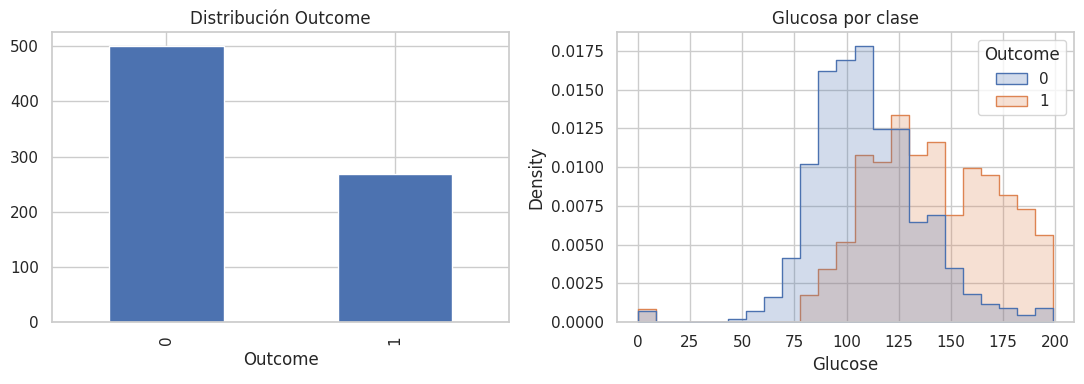

In [3]:
# Exploración descriptiva exigida por el mini-hackatón
print('Dimensiones:', df.shape)
print('Distribución de clase (%):')
print((df['Outcome'].value_counts(normalize=True)*100).round(2).sort_index())
print('Estadísticas descriptivas:')
display(df.describe().T.round(2))
print('Ceros fisiológicamente implausibles (antes de imputación):')
print((df[zero_missing]==0).sum() if 'zero_missing' in globals() else
      (df[[c for c in ['Glucose','BloodPressure','SkinThickness','Insulin','BMI'] if c in df]]==0).sum())
fig,axs=plt.subplots(1,2,figsize=(11,4))
df['Outcome'].value_counts().sort_index().plot.bar(ax=axs[0],title='Distribución Outcome')
df[[c for c in ['Glucose','BMI','Age'] if c in df]].hist(ax=axs[1]) if False else None
sns.histplot(data=df,x='Glucose',hue='Outcome',ax=axs[1],element='step',stat='density',common_norm=False)
axs[1].set_title('Glucosa por clase');plt.tight_layout();plt.show()

## 3. Modelos de referencia
Se conservan baseline mayoritario, regresión logística y Random Forest para comparación histórica. La V3 incorpora Gradient Boosting en el procedimiento de selección. La tabla inicial de CV utiliza umbral 0.50 y **no** determina por sí sola el modelo final.

In [4]:
# Imputación ajustada en cada fold; estandarización solo para regresión logística
models={
 'Baseline':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',DummyClassifier(strategy='most_frequent'))]),
 'Regresión logística':Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',LogisticRegression(max_iter=2000,random_state=SEED))]),
 'Random Forest':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=250,min_samples_leaf=4,random_state=SEED,n_jobs=-1))])
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
scoring={'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','auc':'roc_auc'}
cv_rows=[]
for name,model in models.items():
    s=cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1,error_score='raise')
    row={'modelo':name}
    for metric in scoring:
        row[metric+'_media']=float(s['test_'+metric].mean())
        row[metric+'_std']=float(s['test_'+metric].std(ddof=1))
    cv_rows.append(row)
cv_df=pd.DataFrame(cv_rows)
print(cv_df.round(3).to_string(index=False))
cv_df.to_csv(OUT/'validacion_cruzada.csv',index=False)

             modelo  accuracy_media  accuracy_std  precision_media  precision_std  recall_media  recall_std  f1_media  f1_std  auc_media  auc_std
           Baseline           0.651         0.002            0.000          0.000         0.000       0.000     0.000   0.000      0.500    0.000
Regresión logística           0.788         0.021            0.764          0.067         0.575       0.025     0.655   0.027      0.843    0.021
      Random Forest           0.767         0.012            0.705          0.047         0.580       0.046     0.634   0.019      0.831    0.024


## 4. Selección con objetivos simultáneos y validación anidada
La función `seleccionar` obtiene probabilidades fuera de fold en el subconjunto de entrenamiento y busca una combinación con recall ≥0.80 y especificidad ≥0.70. Entre las elegibles prioriza especificidad, luego recall y AUC; si ninguna cumple, maximiza el mínimo cumplimiento relativo de ambas metas. En la validación anidada se repite **toda** la selección en cada fold externo; después se vuelve a seleccionar sobre el entrenamiento completo para la evaluación final. Los resultados externos estiman generalización del procedimiento, no son garantía de cumplir las metas.

In [5]:
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_curve
from sklearn.model_selection import cross_val_predict, StratifiedKFold

META_RECALL, META_SPEC = .80, .70
candidatos = {}
for C in [0.1, 1.0, 10.0]:
    for peso in [None, 'balanced']:
        candidatos[f'Logistica_C{C}_peso{peso}'] = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', LogisticRegression(C=C, class_weight=peso, max_iter=3000, random_state=SEED))])
for hoja in [2, 5, 10]:
    for peso in [None, 'balanced']:
        candidatos[f'RF_hoja{hoja}_peso{peso}'] = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=hoja,
                 class_weight=peso, random_state=SEED, n_jobs=-1))])
for tasa in [.05, .10]:
    candidatos[f'GradientBoosting_lr{tasa}'] = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', GradientBoostingClassifier(learning_rate=tasa, n_estimators=120,
                                            max_depth=2, random_state=SEED))])

UMBRales = np.round(np.arange(.10, .901, .01), 2)
def metricas_binarias(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'recall':tp/(tp+fn) if tp+fn else 0.,
            'especificidad':tn/(tn+fp) if tn+fp else 0.,
            'precision':tp/(tp+fp) if tp+fp else 0.}

def seleccionar(X, y, n_splits=3, return_table=False):
    cv_in = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    filas = []
    for nombre, estimador in candidatos.items():
        p_oof = cross_val_predict(estimador, X, y, cv=cv_in,
                                   method='predict_proba', n_jobs=1)[:, 1]
        auc = roc_auc_score(y, p_oof)
        for umbral in UMBRales:
            m = metricas_binarias(y, (p_oof >= umbral).astype(int))
            filas.append({'modelo':nombre, 'umbral':float(umbral), 'auc_oof':auc, **m})
    tabla = pd.DataFrame(filas)
    tabla['cumple'] = (tabla.recall >= META_RECALL) & (tabla.especificidad >= META_SPEC)
    tabla['cumplimiento_minimo'] = np.minimum(tabla.recall/META_RECALL,
                                             tabla.especificidad/META_SPEC)
    elegibles = tabla[tabla.cumple]
    if len(elegibles):
        mejor = elegibles.sort_values(['especificidad','recall','auc_oof'],
                                     ascending=False).iloc[0]
    else:
        mejor = tabla.sort_values(['cumplimiento_minimo','auc_oof'],
                                  ascending=False).iloc[0]
    return (mejor, tabla) if return_table else mejor

# Validación anidada: selección dentro de cada fold externo, sin consultar su validación
cv_externo = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
externos = []
for k, (idx_tr, idx_val) in enumerate(cv_externo.split(X_train, y_train), 1):
    xtr, xval = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    ytr, yval = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    elegido = seleccionar(xtr, ytr, n_splits=3)
    modelo_fold = clone(candidatos[elegido['modelo']]).fit(xtr, ytr)
    pval = modelo_fold.predict_proba(xval)[:, 1]
    m = metricas_binarias(yval, (pval >= float(elegido['umbral'])).astype(int))
    externos.append({'fold':k, 'modelo':elegido['modelo'],
                     'umbral':float(elegido['umbral']),
                     'auc':roc_auc_score(yval, pval), **m})
nested_df = pd.DataFrame(externos)
print('VALIDACIÓN ANIDADA (folds externos):')
print(nested_df.round(3).to_string(index=False))
print('Promedio externo recall:', round(nested_df.recall.mean(),3),
      '| especificidad:', round(nested_df.especificidad.mean(),3))
nested_df.to_csv(OUT/'validacion_anidada_v3.csv', index=False)

# Selección final: únicamente sobre entrenamiento completo
seleccion, evaluacion = seleccionar(X_train, y_train, n_splits=5, return_table=True)
selected = str(seleccion['modelo']); t = float(seleccion['umbral'])
model = clone(candidatos[selected])
print('\nSELECCIÓN FINAL EN TRAIN:', selected, 'umbral', t)
print('OOF recall', round(seleccion.recall,3),
      'especificidad', round(seleccion.especificidad,3),
      'cumple ambas', bool(seleccion.cumple))
evaluacion.to_csv(OUT/'busqueda_modelo_umbral_v3.csv', index=False)

VALIDACIÓN ANIDADA (folds externos):
 fold                 modelo  umbral   auc  TN  FP  FN  TP  recall  especificidad  precision
    1  RF_hoja2_pesobalanced    0.36 0.854  61  19   9  34   0.791          0.762      0.642
    2      RF_hoja2_pesoNone    0.31 0.815  54  26   8  35   0.814          0.675      0.574
    3 RF_hoja10_pesobalanced    0.42 0.869  59  21   9  34   0.791          0.738      0.618
    4     RF_hoja10_pesoNone    0.34 0.812  58  22   8  35   0.814          0.725      0.614
    5  RF_hoja5_pesobalanced    0.42 0.825  60  20  10  32   0.762          0.750      0.615
Promedio externo recall: 0.794 | especificidad: 0.73

SELECCIÓN FINAL EN TRAIN: RF_hoja5_pesobalanced umbral 0.41
OOF recall 0.804 especificidad 0.745 cumple ambas True


## 5. Evaluación final en test (referencia histórica)
El modelo y el umbral ya quedaron fijados usando solo entrenamiento. El test se utiliza para reportar métricas y la comparación A/B, **sin cambiar posteriormente la configuración para perseguir el objetivo**. Como V1 y V2 ya utilizaron esta partición, la interpretación de V3 debe reconocer el riesgo de reutilización del test.

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:,1]
pred05 = (prob >= .50).astype(int)
predopt = (prob >= t).astype(int)
def metric_row(nombre, pred):
    m = metricas_binarias(y_test, pred)
    return {'escenario':nombre, 'accuracy':accuracy_score(y_test,pred),
            'precision':precision_score(y_test,pred,zero_division=0),
            'recall':m['recall'], 'especificidad':m['especificidad'],
            'f1':f1_score(y_test,pred,zero_division=0),
            'auc':roc_auc_score(y_test,prob), **{k:m[k] for k in ['TN','FP','FN','TP']}}
results = pd.DataFrame([metric_row('A: umbral 0.50',pred05),
                        metric_row(f'B: umbral {t:.2f}',predopt)])
print(results.round(4).to_string(index=False))
cumple_test = bool((results.iloc[1].recall >= META_RECALL) and
                   (results.iloc[1].especificidad >= META_SPEC))
print('OBJETIVO SMART EN TEST:', 'CUMPLE' if cumple_test else 'NO CUMPLE')
results.to_csv(OUT/'metricas_test_v3.csv',index=False)

     escenario  accuracy  precision  recall  especificidad     f1    auc  TN  FP  FN  TP
A: umbral 0.50    0.7468     0.6316  0.6667           0.79 0.6486 0.8157  79  21  18  36
B: umbral 0.41    0.7403     0.5921  0.8333           0.69 0.6923 0.8157  69  31   9  45
OBJETIVO SMART EN TEST: NO CUMPLE


## 6. Curvas ROC y precision-recall; matriz de confusión
La ROC/AUC mide discriminación independiente del umbral. La curva precision-recall permite examinar el compromiso entre detección y falsas alarmas. Las gráficas usan las probabilidades del modelo fijado antes del test.

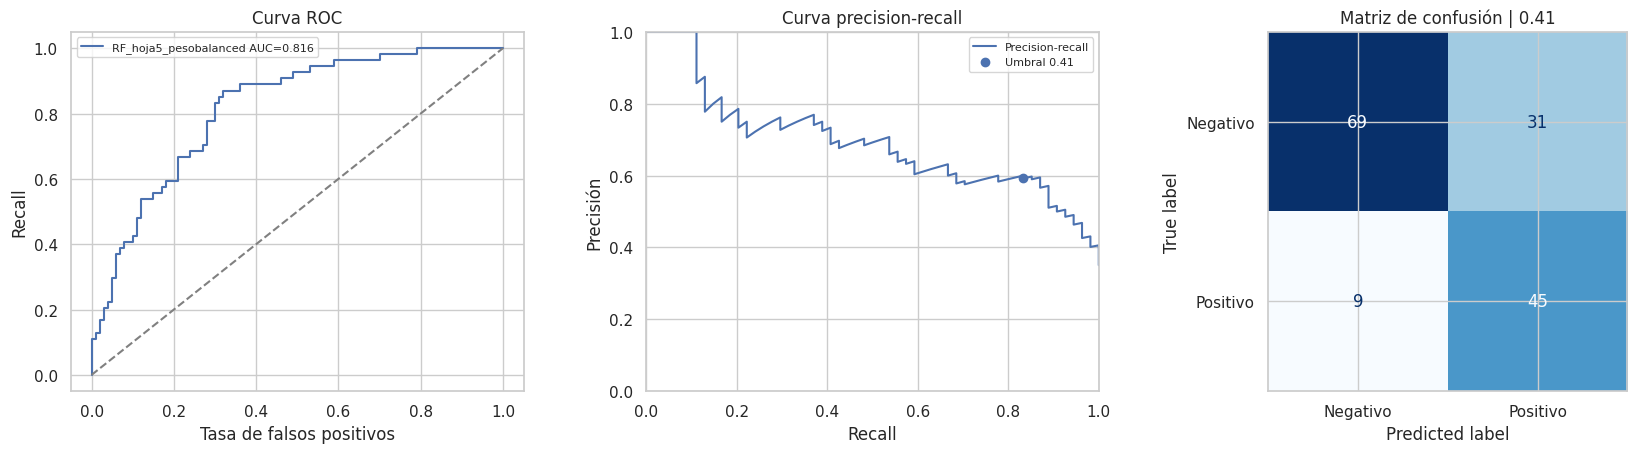

In [7]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
fig, axs = plt.subplots(1, 3, figsize=(17, 4.7))
fpr, tpr, _ = roc_curve(y_test, prob)
axs[0].plot(fpr,tpr,label=f'{selected} AUC={roc_auc_score(y_test,prob):.3f}')
axs[0].plot([0,1],[0,1],'--',color='gray')
axs[0].set(xlabel='Tasa de falsos positivos',ylabel='Recall',title='Curva ROC')
axs[0].legend(fontsize=8)
pr, re, _ = precision_recall_curve(y_test,prob)
axs[1].plot(re,pr,label='Precision-recall')
axs[1].scatter([results.iloc[1].recall],[results.iloc[1].precision],
               label=f'Umbral {t:.2f}',zorder=4)
axs[1].set(xlabel='Recall',ylabel='Precisión',title='Curva precision-recall',xlim=(0,1),ylim=(0,1))
axs[1].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(y_test,predopt,labels=[0,1],
                                        display_labels=['Negativo','Positivo'],
                                        cmap='Blues',ax=axs[2],colorbar=False)
axs[2].set_title(f'Matriz de confusión | {t:.2f}')
plt.tight_layout();plt.savefig(OUT/'curvas_y_matriz_v3.png',dpi=160);plt.show()

## 7. Simulación A/B pareada
A = umbral 0.50; B = umbral seleccionado en entrenamiento. Se comparan las mismas personas; no es una prueba A/B aleatorizada ni una validación clínica. McNemar compara aciertos discordantes, no equivalencia ni superioridad clínica.

In [8]:
correct_a=(pred05==y_test.to_numpy()); correct_b=(predopt==y_test.to_numpy())
a_only=int(np.sum(correct_a & ~correct_b)); b_only=int(np.sum(~correct_a & correct_b))
discordantes=a_only+b_only
p_val=float(binomtest(min(a_only,b_only),n=discordantes,p=.5,
                      alternative='two-sided').pvalue) if discordantes else 1.0
ab=pd.DataFrame([{'A':'Umbral 0.50','B':f'Umbral {t:.2f}',
    'aciertos_solo_A':a_only,'aciertos_solo_B':b_only,
    'discordantes':discordantes,'p_mcnemar_exacto':p_val,
    'delta_FN_B_menos_A':int(results.iloc[1].FN-results.iloc[0].FN),
    'delta_FP_B_menos_A':int(results.iloc[1].FP-results.iloc[0].FP),
    'delta_recall_B_menos_A':float(results.iloc[1].recall-results.iloc[0].recall),
    'delta_especificidad_B_menos_A':float(results.iloc[1].especificidad-results.iloc[0].especificidad)}])
print(ab.round(4).to_string(index=False))
ab.to_csv(OUT/'experimento_ab_v3.csv',index=False)

          A           B  aciertos_solo_A  aciertos_solo_B  discordantes  p_mcnemar_exacto  delta_FN_B_menos_A  delta_FP_B_menos_A  delta_recall_B_menos_A  delta_especificidad_B_menos_A
Umbral 0.50 Umbral 0.41               10                9            19               1.0                  -9                  10                  0.1667                           -0.1


## 8. Dashboard y registro reproducible
El dashboard resume la validación anidada, los resultados de test, las metas SMART y el intercambio entre errores FN/FP. Se guardan CSV, PNG y JSON en `resultados_pima`. Los promedios de folds externos son descriptivos y no equivalen a una prueba externa clínica.

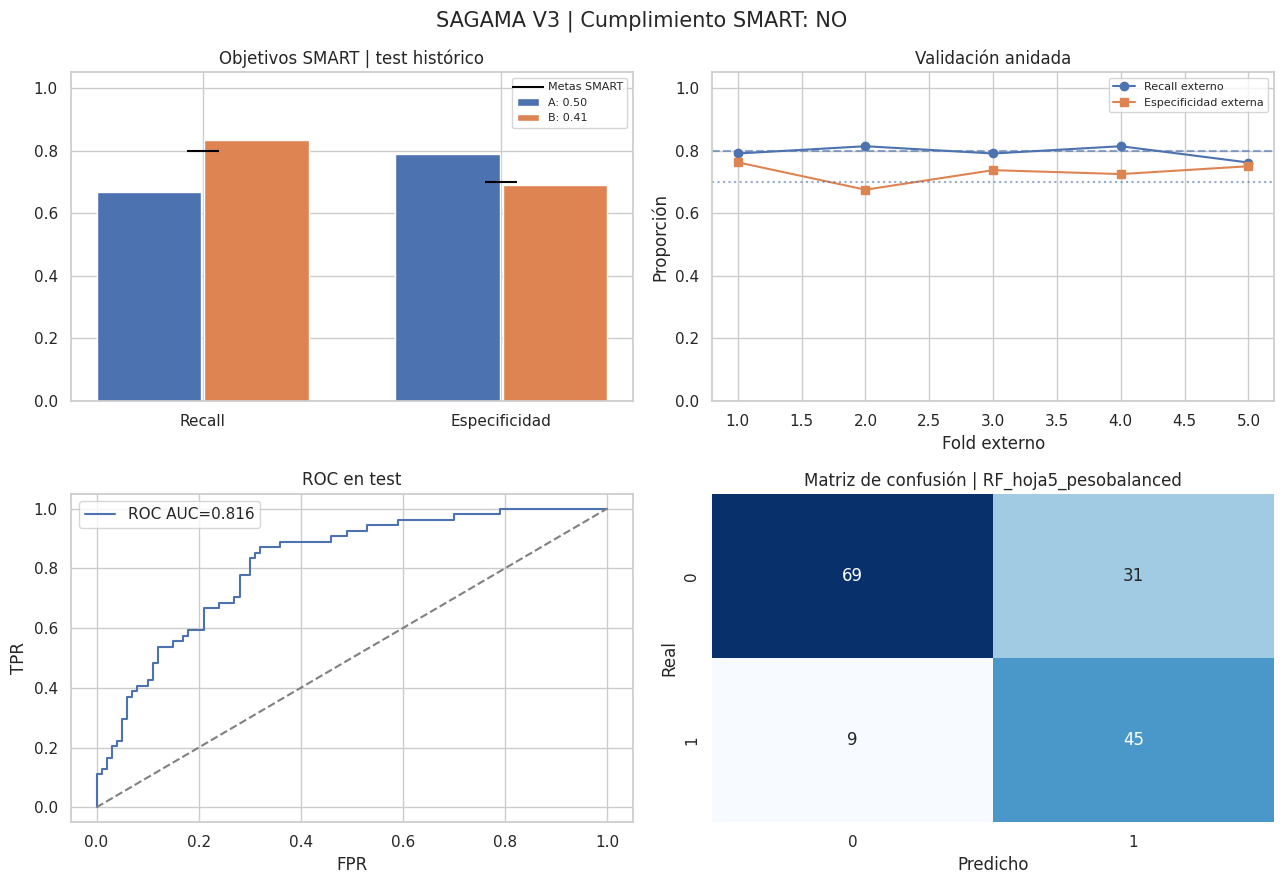

Resultados guardados en: /content/resultados_pima


In [9]:
fig,axs=plt.subplots(2,2,figsize=(13,9))
ax=axs[0,0]
cols=['recall','especificidad']; xx=np.arange(2)
ax.bar(xx-.18,[results.iloc[0][c] for c in cols],width=.35,label='A: 0.50')
ax.bar(xx+.18,[results.iloc[1][c] for c in cols],width=.35,label=f'B: {t:.2f}')
ax.scatter([0,1],[META_RECALL,META_SPEC],marker='_',s=500,color='black',label='Metas SMART')
ax.set_xticks(xx, ['Recall','Especificidad']);ax.set_ylim(0,1.05);ax.legend(fontsize=8)
ax.set_title('Objetivos SMART | test histórico')
ax=axs[0,1]
ax.plot(nested_df.fold,nested_df.recall,'o-',label='Recall externo')
ax.plot(nested_df.fold,nested_df.especificidad,'s-',label='Especificidad externa')
ax.axhline(META_RECALL,ls='--',alpha=.6);ax.axhline(META_SPEC,ls=':',alpha=.6)
ax.set(xlabel='Fold externo',ylabel='Proporción',ylim=(0,1.05),title='Validación anidada')
ax.legend(fontsize=8)
ax=axs[1,0];ax.plot(fpr,tpr,label=f'ROC AUC={roc_auc_score(y_test,prob):.3f}')
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='FPR',ylabel='TPR',title='ROC en test');ax.legend()
ax=axs[1,1]
sns.heatmap(confusion_matrix(y_test,predopt,labels=[0,1]),annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax)
ax.set(xlabel='Predicho',ylabel='Real',title=f'Matriz de confusión | {selected}')
fig.suptitle('SAGAMA V3 | Cumplimiento SMART: '+('SÍ' if cumple_test else 'NO'),fontsize=15)
plt.tight_layout();fig.savefig(OUT/'dashboard_v3.png',dpi=170,bbox_inches='tight');plt.show()
log={'dataset':source,'semilla':SEED,'split':'80/20 estratificado',
     'cv_externa':5,'cv_interna':3,'cv_seleccion_final':5,
     'modelo_final':selected,'umbral_final':t,
     'recall_test':float(results.iloc[1].recall),
     'especificidad_test':float(results.iloc[1].especificidad),
     'cumple_smart_test':cumple_test,
     'limitacion':'Test ya examinado en V1/V2; no es evaluación prospectiva independiente'}
(OUT/'registro_experimento_v3.json').write_text(json.dumps(log,indent=2,ensure_ascii=False),encoding='utf-8')
print('Resultados guardados en:',OUT.resolve())

## 9. Interpretación y limitaciones
- **Selección:** se compararon regresión logística, Random Forest y Gradient Boosting. La combinación modelo-umbral se selecciona usando entrenamiento, priorizando simultáneamente recall ≥80% y especificidad ≥70%.
- **Validación:** los cinco folds externos estiman el rendimiento del proceso de selección completo; se reportan medias y variabilidad sin ocultar folds desfavorables.
- **Evaluación:** el cumplimiento SMART se calcula explícitamente sobre test y **no se presupone**. El conjunto de prueba ya se utilizó en V1/V2: cualquier interpretación de V3 debe reconocer esa exposición previa.
- **Simulación A/B:** comparar umbral 0.50 frente al optimizado implica trade-offs entre FN y FP. McNemar no demuestra beneficio clínico.
- **Alcance:** dataset histórico, población específica, sin validación externa ni calibración clínica. No apto para diagnóstico.
- **Colaboración:** completar en README la contribución de los cuatro integrantes, roles Driver/Navigator y commits reales.